# Create 2D configuration example

Number of neurons: 639
Creating configuration: 2D_initial_configurations/2D_neurons_params_square_SW_agg_nc10_s0.2000_L3.0_rho71_d0.15.txt
Creating configuration: 2D_created_networks/2D_adjacency_matrix_square_SW_agg_nc10_s0.2000_L3.0_rho71_l1.00_d0.15.txt
[[  0   0   0 ...   0   0   0]
 [  0   0   0 ...   0   0   0]
 [  0   0   0 ...   0   0   0]
 ...
 [  0   0   0 ...   0   0   0]
 [  0 126   0 ...   0   0   0]
 [  0   0   0 ...   0   0   0]]
Properties of the ADJACENCY MATRIX:
  mean_degree: 107.32951945080092
  clustering_coefficient: 0.8066087795089151
  average_path_length: 1.9685827052673566
  degree_assortativity: -0.1181496709653358
  modularity: 0.18537463091661177


d:\Ander\Doctorado\Articulo_ProceedingsB\Code\functions_create_networks.py:2830: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


FileNotFoundError: [Errno 2] No such file or directory: 'figures_TFM/spatial_distribution_and_adjacency.png'

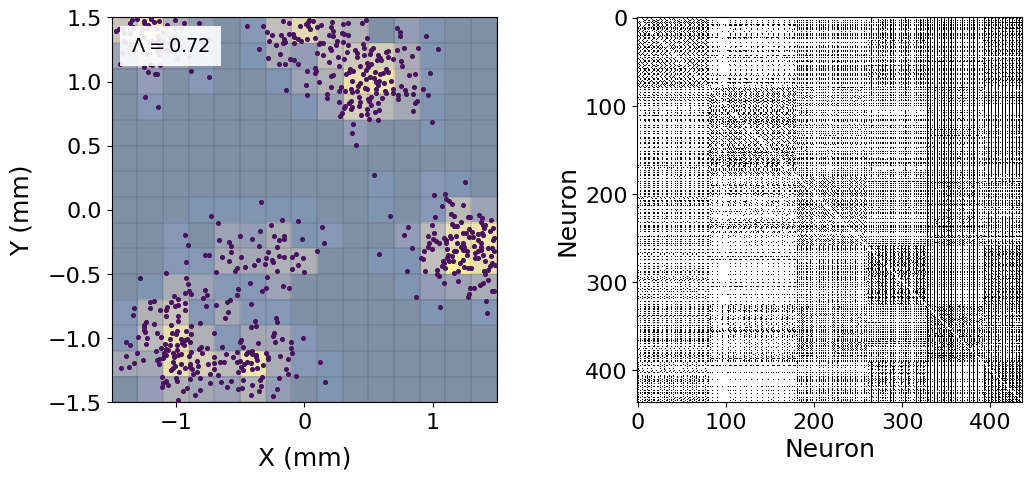

In [17]:
import subprocess
from pathlib import Path
from matplotlib.pylab import seed
import numpy as np
import matplotlib.pyplot as plt
from pypalettes import load_cmap 
import importlib
import functions_create_networks as fcn
importlib.reload(fcn)

fcn.compile_c_codes()

parameters2D = {
    "L": 3.0, # Length of the square domain (mm) or diameter of the circular domain (mm)
    "rho": 71, # Neuron density (neurons/mm^2)
    "soma_diameter": 0.015, # Diameter of the soma (mm)
    "d_mean": 0.15, # Dendritic tree diameter (mm) Gaussian distribution
    "d_sigma": 0.02, # Standard deviation of the dendritic tree diameter (mm)
    "l_mean": 1.0, # Mean axon length (mm) Rayleigh distribution
    "segment_length": 0.01, # Segment length for axon growth (mm)
    "sigma_axon_angle": 0.1, # Standard deviation of the axon angle (radians)
    "agg": 1, # Control parameter for the aggregation of neurons
    "n_centers": 10, # Number of centers for the aggregation of neurons
    "base_sigma": 0.2, # Base standard deviation for aggregation centers (mm)
    "BC_type": "SW",  # Boundary conditions type (PBC: Periodic Boundary Conditions, SW: Sticky Walls)
    "geometry": "square", # Geometry of the domain (square or circle)
    "seed": 0
}
alpha = 0.2

if parameters2D["geometry"] == "circle" and parameters2D["BC_type"] == "PBC":
    raise ValueError("Periodic Boundary Conditions (PBC) are not compatible with a circular geometry. Please choose 'SW' for BC_type or change the geometry to 'square'.")

if parameters2D["geometry"] == "square" or parameters2D["geometry"] == "squareLongRange":
    N = int(parameters2D["rho"] * parameters2D["L"]**2) # Total number of neurons
elif parameters2D["geometry"] == "circle":
    R = parameters2D["L"] / np.sqrt(np.pi)
    print(f"Effective radius of the circular domain: {R:.2f} mm")
    N = int(parameters2D["rho"] * np.pi * R**2) # Total number of neurons, same as in the square case for the same L, but we keep it here for clarity

# N = int((parameters2D["L"] / parameters2D["soma_diameter"])**2)

print(f"Number of neurons: {N}")
parametersDynamics = {
    "max_exc_weight": 7,
    "max_inh_weight": 0.5,
    "noise_max": 4,
    "sim_time": 20000,
    "seed": 42
}

simulate_dynamics = False
new_sim = True

filename_neuron_params = fcn.run_2D_tune_positions(parameters2D, new_sim=new_sim)
filename_network_tries = fcn.create_network2D(parameters2D, new_sim=new_sim)
M = fcn.load_A(filename_network_tries)
print(M)
A, filename_adj = fcn.modify_A_alpha2D(M, alpha, parameters2D, new_sim=new_sim, GC = True)

propertiesA = fcn.properties_of_network(A)
print("Properties of the ADJACENCY MATRIX:")

for prop, value in propertiesA.items():
    if prop == 'degree_distribution':
        continue
    else:
        print(f"  {prop}: {value}")

order = None

if simulate_dynamics:

    parametersDynamics["out_filename"] = filename_adj
    filename_dynamics = fcn.run_dynamics_2D(
        parametersDynamics,
        parameters2D,
        alpha,
        new_sim=new_sim, 
        show_prints_c = True
    )

    F, F_binary, F_ordered, order_communities, communities = fcn.build_F_matrix(filename_dynamics, parametersDynamics["sim_time"], N = len(A))

    order = order_communities
    
    propertiesF = fcn.properties_of_network(F_binary)
    print("Properties of the FUNCTIONAL NETWORK:")
    for prop, value in propertiesF.items():
        if prop == 'degree_distribution':
            continue
        else:
            print(f"  {prop}: {value}")
    
    print(A.shape)
    print(len(order))
    print(np.min(order), np.max(order))

    print("Fuera de plot:")
    print("filename_adj =", filename_adj)
    print("A.shape =", A.shape)

fcn.plot_spatial_distr_AND_adjacency(filename_neuron_params, A, parameters2D, order = order)

In [ ]:
# To use ths cell you must set simulate_dynamics to True in the previous cell and run it. Otherwise, the dynamics simulation will be skipped and no plots will be generated.

import importlib
import functions_create_networks as fcn
importlib.reload(fcn)

if simulate_dynamics:
    fcn.plot_F_rusterGNA(filename_dynamics, F_binary, order = order, SIM_TIME = parametersDynamics["sim_time"], N = len(A), xlim = 2000)
else:
    print("Dynamics simulation skipped. Set simulate_dynamics to True to run the simulation and plot the results.") 

# Create 3D network configuration

Number of neurons: 5400
Creating configuration: 3D_initial_configurations/3D_neurons_params_cube_SW_agg_nc20_s0.2000_L3.0_h1.00_rho600_d0.15.txt
Creating configuration: 3D_created_networks/3D_adjacency_matrix_cube_SW_agg_nc20_s0.2000_L3.0_h1.00_rho600_l1.00_d0.15.txt
Parameters loaded from file: 3D_initial_configurations/3D_neurons_params_cube_SW_agg_nc20_s0.2000_L3.0_h1.00_rho600_d0.15.txt
L = 3.0
height = 1.00
rho = 600 --> N = 5400
soma_diameter = 0.015
d_mean = 0.150
d_sigma = 0.020
l_mean = 1.000
l_sigma = 0.523
sigma_rayleigh = 0.798
segment_length = 0.010
sigma_pol = 0.100
sigma_azi = 0.100
nc = 20
base_sigma = 0.2000
BC_type = SW
Geometry = cube
Header line skipped: X	Y	Z	Soma_Diameter	Dendrite_Diameter	agg_center	center_x	center_y	center_z



Trials (intersections) = 275124587
Links created          = 275124587
Acceptance ratio       = 1.000000
Unique directed links = 3412643


[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]


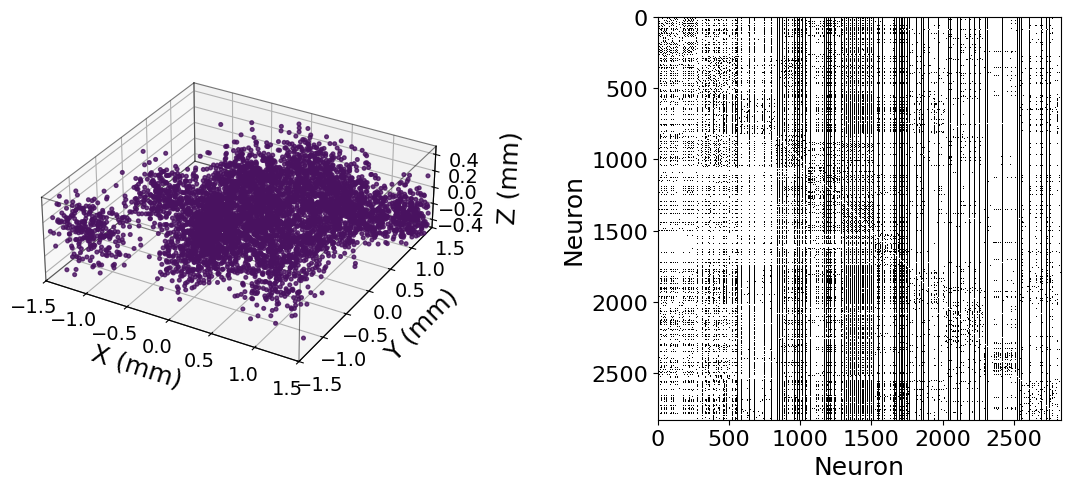

(np.float64(0.7727871452546297),
 np.float64(0.7743842962707677),
 np.float64(0.06762468715056755))

In [19]:
import subprocess
from pathlib import Path
from matplotlib.pylab import seed
import numpy as np
import matplotlib.pyplot as plt
from pypalettes import load_cmap 
import importlib
import functions_create_networks as fcn
importlib.reload(fcn)

fcn.compile_c_codes3D()

parameters3D = {
    "L": 3.0, # Length of the square domain (mm) or diameter of the circular domain (mm)
    "height": 1.0, # Height of the cylinder domain (mm), only used if geometry is "cylinder"
    "rho": 600, # Neuron density (neurons/mm^2)
    "soma_diameter": 0.015, # Diameter of the soma (mm)
    "d_mean": 0.15, # Dendritic tree diameter (mm) Gaussian distribution
    "d_sigma": 0.02, # Standard deviation of the dendritic tree diameter (mm)
    "l_mean": 1., # Mean axon length (mm) Rayleigh distribution
    "segment_length": 0.01, # Segment length for axon growth (mm)
    "sigma_pol": 0.1, # Standard deviation of the axon angle (radians)
    "sigma_azi": 0.1, # Standard deviation of the azimuthal angle (radians)
    "agg": 1, # Control parameter for the aggregation of neurons
    "n_centers": 20, # Number of centers for the aggregation of neurons
    "base_sigma": 0.2, # Base standard deviation for aggregation centers (mm)
    "BC_type": "SW",  # Boundary conditions type (PBC: Periodic Boundary Conditions, SW: Sticky Walls)
    "geometry": "cube", # Geometry of the domain (cube or sphere)
    "seed": 0,
}

if parameters3D["geometry"] == "cylinder" and parameters3D["BC_type"] == "PBC":
    raise ValueError("Periodic Boundary Conditions (PBC) are not compatible with a cylindrical geometry. Please choose 'SW' for BC_type or change the geometry to 'cube'.")
if parameters3D["geometry"] == "cube" or parameters3D["geometry"] == "cubeLongRange" or parameters3D["geometry"] == "cubeBiased":
    N = int(parameters3D["rho"] * parameters3D["L"]**2 * parameters3D["height"]) # Total number of neurons
elif parameters3D["geometry"] == "cylinder":
    R = parameters3D["L"] / np.sqrt(np.pi)
    print(f"Effective radius of the cylinder domain: {R:.2f} mm")
    N = int(parameters3D["rho"] * np.pi * R**2 * parameters3D["height"]) # Total number of neurons, same as in the cube case for the same L, but we keep it here for clarity

alpha = 0.2

print(f"Number of neurons: {N}")
parametersDynamics = {
    "max_exc_weight": 15,
    "max_inh_weight": 0.5,
    "noise_max": 3,
    "sim_time": 2000,
    "seed": 0
}


simulate_dynamics = False
new_sim = True

filename_neuron_params = fcn.run_3D_tune_positions(parameters3D, new_sim = new_sim)
filename_network_tries = fcn.create_network3D(parameters3D, new_sim = new_sim, show_prints_c = True)
M = fcn.load_A3D(filename_network_tries, N)
print(M)
A, filename_adj, nodes_GSCC = fcn.modify_A_alpha3D_fast(M, alpha, parameters3D=parameters3D, new_sim=True, GC=True)
# X,Y,Z ,_,_,_ = fcn.load_neuron_params_3D(filename_neuron_params)
# Gini = fcn.compute_gini_3D(X, Y, Z, parameters3D["L"], parameters3D["height"], geometry=parameters3D["geometry"])
# propertiesA = fcn.properties_of_network(A)
# print("Properties of the ADJACENCY MATRIX:")

# for prop, value in propertiesA.items():
#     if prop == 'degree_distribution':
#         continue
#     else:
#         print(f"  {prop}: {value}")

# order = None

# print(f"Gini coefficient of the spatial distribution: {Gini:.6f}")
if simulate_dynamics:

    parametersDynamics["out_filename"] = filename_adj
    filename_dynamics = fcn.run_dynamics_3D(
        parametersDynamics,
        parameters3D,
        alpha,
        new_sim=new_sim
    )

    F, F_binary, F_ordered, order_communities, communities = fcn.build_F_matrix(filename_dynamics, parametersDynamics["sim_time"], N = len(A))
    order = order_communities

    propertiesF = fcn.properties_of_network(F_binary)
    print("Properties of the FUNCTIONAL NETWORK:")
    for prop, value in propertiesF.items():
        if prop == 'degree_distribution':
            continue
        else:
            print(f"  {prop}: {value}")

if parameters3D["agg"] == 0: 
    order = None
    if simulate_dynamics:
        F_ordered = F_binary

# Cambiar grid en funcion del tamaño de la neurona

fcn.plot_spatial_distr_AND_adjacency_3D(filename_neuron_params, filename_adj, parameters3D, order = None)

# Structural properties (Fig.1)

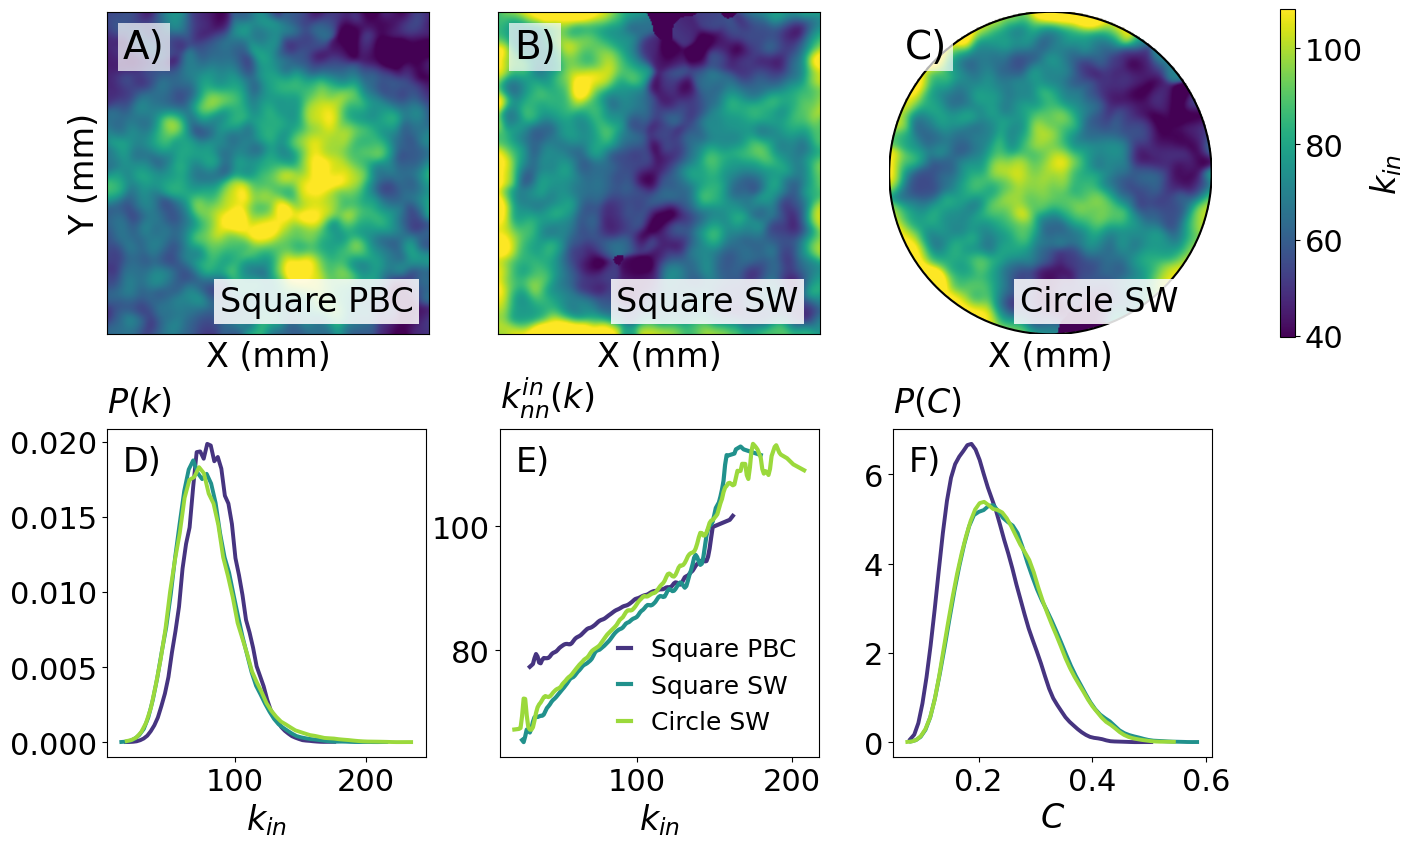

# Gini color map (Fig.2)

C:\Users\Usuario\AppData\Local\Temp\ipykernel_11912\48074351.py:48: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(wspace=0.0)


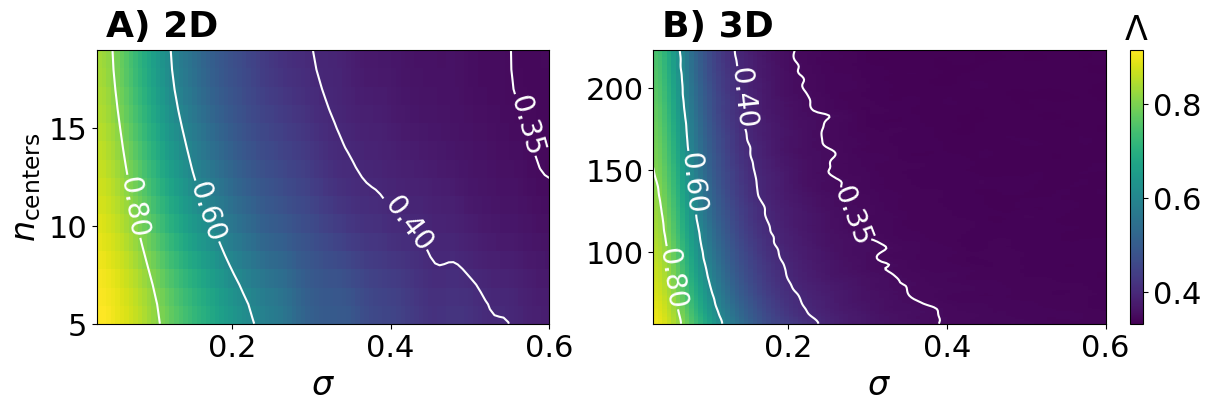

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

cell_size = 0.15  # mm
n_grid = int(2.0 / cell_size)

file_2D = f"data_for_figures/gini2D_n_grid{n_grid}_mean.txt"
file_3D = f"data_for_figures/gini3D_n_grid{n_grid}_mean.txt"

data_2D = pd.read_csv(file_2D, sep="\t")
data_3D = pd.read_csv(file_3D, sep="\t")


def make_gini_grid(df, value_col):
    pivot = df.pivot(
        index="n_centers",
        columns="base_sigma",
        values=value_col
    ).sort_index()

    x = pivot.columns.to_numpy(dtype=float)
    y = pivot.index.to_numpy(dtype=float)
    Z = pivot.to_numpy()

    return x, y, Z


x_2D, y_2D, Z_2D = make_gini_grid(data_2D, "Gini_mean")
x_3D, y_3D, Z_3D = make_gini_grid(data_3D, "Gini_Slices_mean")

Z_2D_smooth = gaussian_filter(Z_2D, sigma=2.0)
Z_3D_smooth = gaussian_filter(Z_3D, sigma=2.0)

# Misma escala para ambos mapas
vmin = min(np.nanmin(Z_2D_smooth), np.nanmin(Z_3D_smooth))
vmax = max(np.nanmax(Z_2D_smooth), np.nanmax(Z_3D_smooth))

levels = [0.35, 0.4, 0.6, 0.8]

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4),
    sharey=False, constrained_layout=True
)

fig.subplots_adjust(wspace=0.0)

# =====================
# A) 2D
# =====================
ax = axes[0]

im = ax.imshow(
    Z_2D_smooth,
    origin="lower",
    aspect="auto",
    extent=[x_2D.min(), x_2D.max(), y_2D.min(), y_2D.max()],
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    interpolation="nearest"
)

cs = ax.contour(
    x_2D, y_2D, Z_2D_smooth,
    levels=levels,
    colors="white",
    linewidths=1.5,
    linestyles="-"
)

ax.clabel(cs, inline=True, fontsize=20, fmt="%.2f")

ax.set_xlabel(r"$\sigma$", fontsize=24)
ax.set_ylabel(r"$n_\mathrm{centers}$", fontsize=24)
ax.tick_params(labelsize=22)

ax.text(
    0.02, 1.05, "A) 2D",
    transform=ax.transAxes,
    fontsize=26,
    fontweight="bold",
    color="black"
)

# =====================
# B) 3D
# =====================
ax = axes[1]

im = ax.imshow(
    Z_3D_smooth,
    origin="lower",
    aspect="auto",
    extent=[x_3D.min(), x_3D.max(), y_3D.min(), y_3D.max()],
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    interpolation="nearest"
)

cs = ax.contour(
    x_3D, y_3D, Z_3D_smooth,
    levels=levels,
    colors="white",
    linewidths=1.5,
    linestyles="-"
)

ax.clabel(cs, inline=True, fontsize=20, fmt="%.2f")

ax.set_xlabel(r"$\sigma$", fontsize=24)
# ax.set_ylabel(r"$n_\mathrm{centers}$", fontsize=20)
ax.tick_params(labelsize=22)

ax.text(
    0.02, 1.05, "B) 3D",
    transform=ax.transAxes,
    fontsize=26,
    fontweight="bold",
    color="black"
)

# =====================
# Shared colorbar
# =====================
# Después de pintar los dos mapas:
cbar = fig.colorbar(
    im,
    ax=axes.ravel().tolist(),
    location="right",
    shrink= 1,
    pad=0.0,
    fraction=0.035
)

cbar.ax.set_title(r"$\Lambda$", fontsize=24, pad=8)
cbar.ax.tick_params(labelsize=22)

plt.savefig(
    "gini_2D_3D_panel_shared_cbar.pdf",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Depedency of $\langle k_{in}\rangle$ and $GCS$ with $\alpha$ and $\langle \ell\rangle$ (Fig.SM1)

C:\Users\Usuario\AppData\Local\Temp\ipykernel_11912\1678819372.py:389: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


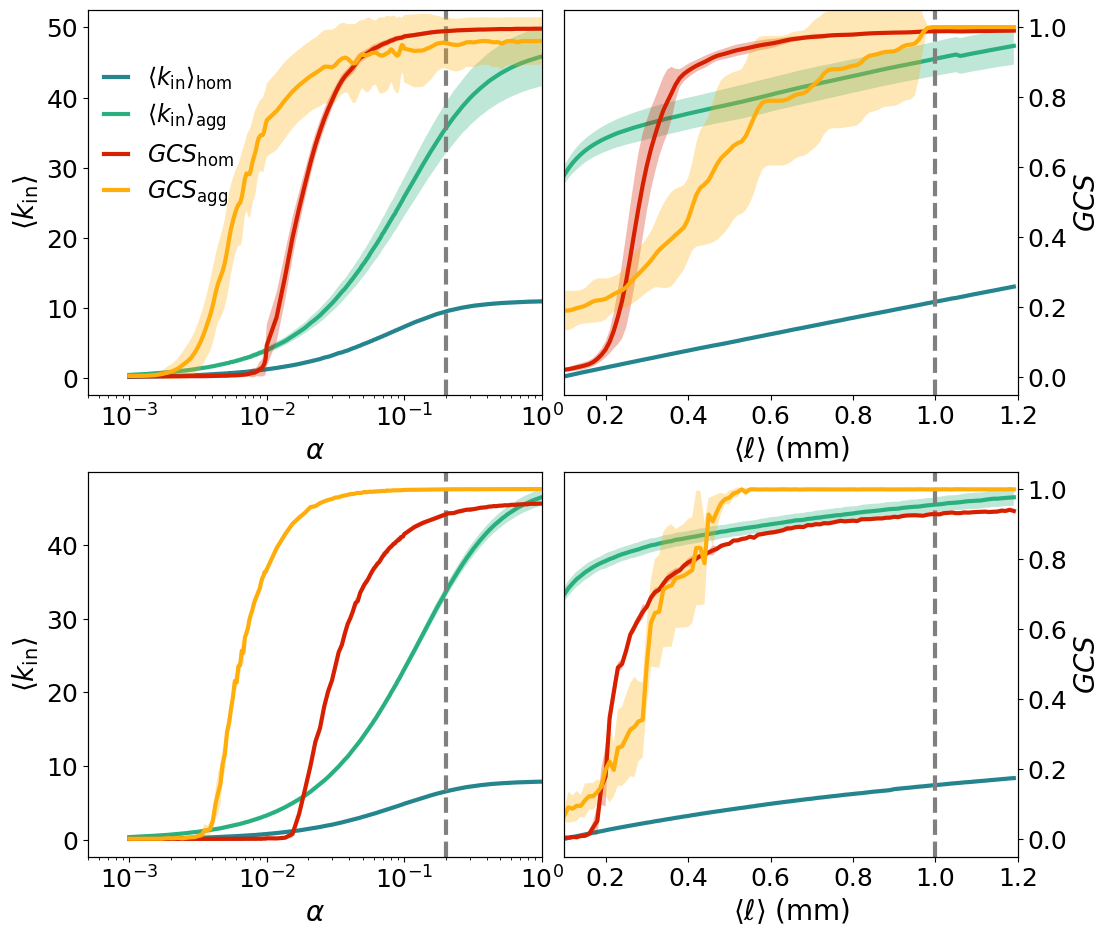

In [6]:
from scipy.ndimage import gaussian_filter1d
import numpy as np
import matplotlib.pyplot as plt
from pypalettes import load_cmap

viridis = load_cmap("viridis")
apricot = load_cmap("Apricot")

# ============================================================
# General parameters
# ============================================================

sigma_smooth = 1
n_sims_2D_alpha = 20

# fig, axes = plt.subplots(
#     2, 2,
#     figsize=(12, 9),
#     sharey="row",
#     gridspec_kw={
#         "wspace": 0.05,
#         "hspace": 0.28
#     }
# )

# ============================================================
# =====================  LOAD ALPHA DATA  ====================
# ============================================================

# -------------------------
# 2D random alpha
# -------------------------
data = np.loadtxt(
    'data_for_figures/2D_kin_GC_vs_alpha_rho71_ran_mean_new.txt',
    skiprows=1
)

alpha_2D = data[:, 0]
kin_mean_2D = data[:, 1]
kin_std_2D = data[:, 2] 
GC_mean_2D = data[:, 3]
GC_std_2D = data[:, 4] 

# -------------------------
# 2D aggregated alpha
# -------------------------
data_agg = np.loadtxt(
    'data_for_figures/2D_kin_GC_vs_alpha_rho71_agg_mean_new.txt',
    skiprows=1
)

alpha_2D_agg = data_agg[:, 0]
kin_mean_2D_agg = data_agg[:, 1]
kin_std_2D_agg = data_agg[:, 2] 
GC_mean_2D_agg = data_agg[:, 3]
GC_std_2D_agg = data_agg[:, 4] 

# -------------------------
# 3D random alpha
# -------------------------
data_3D = np.loadtxt(
    'data_for_figures/3D_kin_GC_vs_alpha_600_ran_mean.txt',
    skiprows=1
)

alpha_3D = data_3D[:, 0]
kin_mean_3D = data_3D[:, 1]
kin_std_3D = data_3D[:, 2]
GC_mean_3D = data_3D[:, 3]
GC_std_3D = data_3D[:, 4]

# -------------------------
# 3D aggregated alpha
# -------------------------
data_3D_agg = np.loadtxt(
    'data_for_figures/3D_kin_GC_vs_alpha_600_agg_mean.txt',
    skiprows=1
)

alpha_3D_agg = data_3D_agg[:, 0]
kin_mean_3D_agg = data_3D_agg[:, 1]
kin_std_3D_agg = data_3D_agg[:, 2]
GC_mean_3D_agg = data_3D_agg[:, 3]
GC_std_3D_agg = data_3D_agg[:, 4]

# -------------------------
# Smooth alpha GCS
# -------------------------
GC_mean_2D_smooth = gaussian_filter1d(GC_mean_2D, sigma=sigma_smooth)
GC_std_2D_smooth = gaussian_filter1d(GC_std_2D, sigma=sigma_smooth)

GC_mean_2D_agg_smooth = gaussian_filter1d(GC_mean_2D_agg, sigma=sigma_smooth)
GC_std_2D_agg_smooth = gaussian_filter1d(GC_std_2D_agg, sigma=sigma_smooth)


# ============================================================
# =======================  LOAD ELL DATA  ====================
# ============================================================

# -------------------------
# 2D random ell
# -------------------------
data = np.loadtxt(
    'data_for_figures/2D_kin_GC_vs_ell_rho71_ran_mean.txt',
    skiprows=1
)

ell_2D = data[:, 0]
kin_mean_2D_ell = data[:, 1]
kin_std_2D_ell = data[:, 2]
GC_mean_2D_ell = data[:, 3]
GC_std_2D_ell = data[:, 4]

# -------------------------
# 2D aggregated ell
# -------------------------
data_agg = np.loadtxt(
    'data_for_figures/2D_kin_GC_vs_ell_rho71_agg_mean.txt',
    skiprows=1
)

ell_2D_agg = data_agg[:, 0]
kin_mean_2D_agg_ell = data_agg[:, 1]
kin_std_2D_agg_ell = data_agg[:, 2]
GC_mean_2D_agg_ell = data_agg[:, 3]
GC_std_2D_agg_ell = data_agg[:, 4]

# -------------------------
# 3D random ell
# -------------------------
data_3D = np.loadtxt(
    'data_for_figures/3D_kin_GC_vs_ell_600_ran_mean.txt',
    skiprows=1
)

ell_3D = data_3D[:, 0]
kin_mean_3D_ell = data_3D[:, 1]
kin_std_3D_ell = data_3D[:, 2]
GC_mean_3D_ell = data_3D[:, 3]
GC_std_3D_ell = data_3D[:, 4]

# -------------------------
# 3D aggregated ell
# -------------------------
data_3D_agg = np.loadtxt(
    'data_for_figures/3D_kin_GC_vs_ell_600_agg_mean.txt',
    skiprows=1
)

ell_3D_agg = data_3D_agg[:, 0]
kin_mean_3D_agg_ell = data_3D_agg[:, 1]
kin_std_3D_agg_ell = data_3D_agg[:, 2]
GC_mean_3D_agg_ell = data_3D_agg[:, 3]
GC_std_3D_agg_ell = data_3D_agg[:, 4]

# -------------------------
# Smooth ell GCS
# -------------------------
GC_mean_2D_ell_smooth = gaussian_filter1d(GC_mean_2D_ell, sigma=sigma_smooth)
GC_std_2D_ell_smooth = gaussian_filter1d(GC_std_2D_ell, sigma=sigma_smooth)

GC_mean_2D_agg_ell_smooth = gaussian_filter1d(GC_mean_2D_agg_ell, sigma=sigma_smooth)
GC_std_2D_agg_ell_smooth = gaussian_filter1d(GC_std_2D_agg_ell, sigma=sigma_smooth)


# ============================================================
# Helper function
# ============================================================

def format_panel(ax, axb, panel_label, show_left_ylabel=True, show_right_ylabel=True):
    ax.tick_params(axis='both', labelsize=16)
    axb.tick_params(axis='y', labelsize=16)

    axb.set_ylim(-0.05, 1.05)

    if not show_left_ylabel:
        ax.set_ylabel("")
        ax.tick_params(axis='y', left=False, labelleft=False)

    if not show_right_ylabel:
        axb.set_ylabel("")
        axb.tick_params(axis='y', right=False, labelright=False)

    ax.text(
        0.88, 0.12, panel_label,
        transform=ax.transAxes,
        fontsize=18,
        ha="center",
        va="top",
        fontweight="bold"
    )


fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 11),
    gridspec_kw={"wspace": 0.05, "hspace": 0.2}
)
color_kin_ran = viridis(0.4)
color_kin_agg = viridis(0.6)

color_GCS_ran = apricot(0.1)
color_GCS_agg = apricot(0.4)
# ======================================================
# A) alpha - 2D
# ======================================================
ax1 = axes[0, 0]
ax1b = ax1.twinx()


ax1.plot(alpha_2D, kin_mean_2D, color=color_kin_ran, lw=3,
         label=r'$\langle k_{\mathrm{in}} \rangle_{\mathrm{hom}}$')
ax1.fill_between(alpha_2D, kin_mean_2D-kin_std_2D, kin_mean_2D+kin_std_2D,
                 color=color_kin_ran, alpha=0.2, edgecolor=None)

ax1.plot(alpha_2D_agg, kin_mean_2D_agg, color=color_kin_agg, lw=3,
         label=r'$\langle k_{\mathrm{in}} \rangle_{\mathrm{agg}}$')
ax1.fill_between(alpha_2D_agg, kin_mean_2D_agg-kin_std_2D_agg, kin_mean_2D_agg+kin_std_2D_agg,
                 color=color_kin_agg, alpha=0.3, edgecolor=None)

ax1b.plot(alpha_2D, GC_mean_2D_smooth, color=color_GCS_ran, lw=3,
          label=r'$GCS_{\mathrm{hom}}$')
ax1b.fill_between(alpha_2D, GC_mean_2D_smooth-GC_std_2D_smooth,
                  GC_mean_2D_smooth+GC_std_2D_smooth,
                  color=color_GCS_ran, alpha=0.3, edgecolor=None)

ax1b.plot(alpha_2D_agg, GC_mean_2D_agg_smooth, color=color_GCS_agg, lw=3,
          label=r'$GCS_{\mathrm{agg}}$')
ax1b.fill_between(alpha_2D_agg, GC_mean_2D_agg_smooth-GC_std_2D_agg_smooth,
                  GC_mean_2D_agg_smooth+GC_std_2D_agg_smooth,
                  color=color_GCS_agg, alpha=0.3, edgecolor=None)

ax1.set_xscale("log")
ax1.set_xlim(0.0005, 1.0)
ax1.axvline(0.2, color="gray", ls="--", lw=3)

ax1.set_xlabel(r'$\alpha$', fontsize=20)
ax1.set_ylabel(r'$\langle k_{\mathrm{in}} \rangle$', fontsize=20)

ax1b.set_ylim(-0.05, 1.05)
ax1b.set_yticks([])
ax1b.set_ylabel("")
ax1b.tick_params(axis="y", right=False, labelright=False)

# ax1.text(0.15, 0.95, "A) 2D",
#          transform=ax1.transAxes, fontsize=20,
#          ha="center", va="top")

# Leyenda dentro del panel A
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax1b.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper left",
    fontsize=17,
    frameon=False,
    ncol=1,          # <-- una Ãºnica columna
    handlelength=1,
    labelspacing=0.4,
    borderaxespad=0.3, 
    bbox_to_anchor=(0.0, 0.9)
)

# ======================================================
# C) alpha - 3D (abajo izquierda)
# ======================================================
ax2 = axes[1, 0]
ax2b = ax2.twinx()

ax2.plot(alpha_3D, kin_mean_3D, color=color_kin_ran, lw=3)
ax2.fill_between(alpha_3D, kin_mean_3D-kin_std_3D, kin_mean_3D+kin_std_3D,
                 color=color_kin_ran, alpha=0.2, edgecolor=None)
ax2.plot(alpha_3D_agg, kin_mean_3D_agg, color=color_kin_agg, lw=3)
ax2.fill_between(alpha_3D_agg, kin_mean_3D_agg-kin_std_3D_agg, kin_mean_3D_agg+kin_std_3D_agg,
                 color=color_kin_agg, alpha=0.3, edgecolor=None)

ax2b.plot(alpha_3D, GC_mean_3D, color=color_GCS_ran, lw=3)
ax2b.fill_between(alpha_3D, GC_mean_3D-GC_std_3D, GC_mean_3D+GC_std_3D,
                  color=color_GCS_ran, alpha=0.3, edgecolor=None)
ax2b.plot(alpha_3D_agg, GC_mean_3D_agg, color=color_GCS_agg, lw=3)
ax2b.fill_between(alpha_3D_agg, GC_mean_3D_agg-GC_std_3D_agg, GC_mean_3D_agg+GC_std_3D_agg,
                  color=color_GCS_agg, alpha=0.3, edgecolor=None)

ax2.set_xscale("log")
ax2.set_xlim(0.0005, 1.0)
ax2.axvline(0.2, color="gray", ls="--", lw=3)

ax2.set_xlabel(r'$\alpha$', fontsize=20)
ax2.set_ylabel(r'$\langle k_{\mathrm{in}} \rangle$', fontsize=20)

ax2b.set_ylim(-0.05, 1.05)
ax2b.set_yticks([])
ax2b.set_ylabel("")
ax2b.tick_params(axis="y", right=False, labelright=False)

# ax2.text(0.15, 0.95, "C) 3D",
#          transform=ax2.transAxes, fontsize=20,
#          ha="center", va="top")

# ======================================================
# B) ell - 2D (arriba derecha)
# ======================================================
ax3 = axes[0, 1]
ax3b = ax3.twinx()

ax3.plot(ell_2D, kin_mean_2D_ell, color=color_kin_ran, lw=3)
ax3.fill_between(ell_2D, kin_mean_2D_ell-kin_std_2D_ell,
                 kin_mean_2D_ell+kin_std_2D_ell,
                 color=color_kin_ran, alpha=0.2, edgecolor=None)

ax3.plot(ell_2D_agg, kin_mean_2D_agg_ell, color=color_kin_agg, lw=3)
ax3.fill_between(ell_2D_agg, kin_mean_2D_agg_ell-kin_std_2D_agg_ell,
                 kin_mean_2D_agg_ell+kin_std_2D_agg_ell,
                 color=color_kin_agg, alpha=0.3, edgecolor=None)

ax3b.plot(ell_2D, GC_mean_2D_ell_smooth, color=color_GCS_ran, lw=3)
ax3b.fill_between(ell_2D, GC_mean_2D_ell_smooth-GC_std_2D_ell_smooth,
                  GC_mean_2D_ell_smooth+GC_std_2D_ell_smooth,
                  color=color_GCS_ran, alpha=0.3, edgecolor=None)

ax3b.plot(ell_2D_agg, GC_mean_2D_agg_ell_smooth, color=color_GCS_agg, lw=3)
ax3b.fill_between(ell_2D_agg, GC_mean_2D_agg_ell_smooth-GC_std_2D_agg_ell_smooth,
                  GC_mean_2D_agg_ell_smooth+GC_std_2D_agg_ell_smooth,
                  color=color_GCS_agg, alpha=0.3, edgecolor=None)

ax3.set_xlim(0.1, 1.2)
ax3.axvline(1.0, color="gray", ls="--", lw=3)

ax3.set_xlabel(r'$\langle \ell \rangle$' + " (mm)", fontsize=20)
ax3.set_ylabel("")
ax3.tick_params(axis="y", left=False, labelleft=False)

ax3b.set_ylim(-0.05, 1.05)
ax3b.set_ylabel(r'$GCS$', fontsize=20)

# ax3.text(0.15, 0.95, "B) 2D",
#          transform=ax3.transAxes, fontsize=20,
#          ha="center", va="top")

# ======================================================
# D) ell - 3D
# ======================================================
ax4 = axes[1, 1]
ax4b = ax4.twinx()

ax4.plot(ell_3D, kin_mean_3D_ell, color=color_kin_ran, lw=3)
ax4.fill_between(ell_3D, kin_mean_3D_ell-kin_std_3D_ell,
                 kin_mean_3D_ell+kin_std_3D_ell,
                 color=color_kin_ran, alpha=0.2, edgecolor=None)
ax4.plot(ell_3D_agg, kin_mean_3D_agg_ell, color=color_kin_agg, lw=3)
ax4.fill_between(ell_3D_agg, kin_mean_3D_agg_ell-kin_std_3D_agg_ell,
                 kin_mean_3D_agg_ell+kin_std_3D_agg_ell,
                 color=color_kin_agg, alpha=0.3, edgecolor=None)

ax4b.plot(ell_3D, GC_mean_3D_ell, color=color_GCS_ran, lw=3)
ax4b.fill_between(ell_3D, GC_mean_3D_ell-GC_std_3D_ell,
                  GC_mean_3D_ell+GC_std_3D_ell, 
                  color=color_GCS_ran, alpha=0.3, edgecolor=None)
ax4b.plot(ell_3D_agg, GC_mean_3D_agg_ell, color=color_GCS_agg, lw=3)
ax4b.fill_between(ell_3D_agg, GC_mean_3D_agg_ell-GC_std_3D_agg_ell,
                  GC_mean_3D_agg_ell+GC_std_3D_agg_ell,
                  color=color_GCS_agg, alpha=0.3, edgecolor=None)

ax4.set_xlim(0.1, 1.2)
ax4.axvline(1.0, color="gray", ls="--", lw=3)

ax4.set_xlabel(r'$\langle \ell \rangle$' + " (mm)", fontsize=20)
ax4.set_ylabel("")
ax4.tick_params(axis="y", left=False, labelleft=False)

ax4b.set_ylabel(r'$GCS$', fontsize=20)
ax4b.set_ylim(-0.05, 1.05)

# ax4.text(0.15, 0.95, "D) 3D",
#          transform=ax4.transAxes, fontsize=20,
#          ha="center", va="top")

# ======================================================
# Global formatting
# ======================================================
for ax in [ax1, ax2, ax3, ax4]:
    ax.tick_params(axis="both", labelsize=18)

for axb in [ax1b, ax2b, ax3b, ax4b]:
    axb.tick_params(axis="y", labelsize=18)

plt.tight_layout()

plt.savefig(
    '2D_3D_kin_GC_vs_alpha_ell_panel.png',
    dpi=600,
    bbox_inches='tight', 
    transparent=True
)

plt.show()

# Axonal length color map (Fig.4)

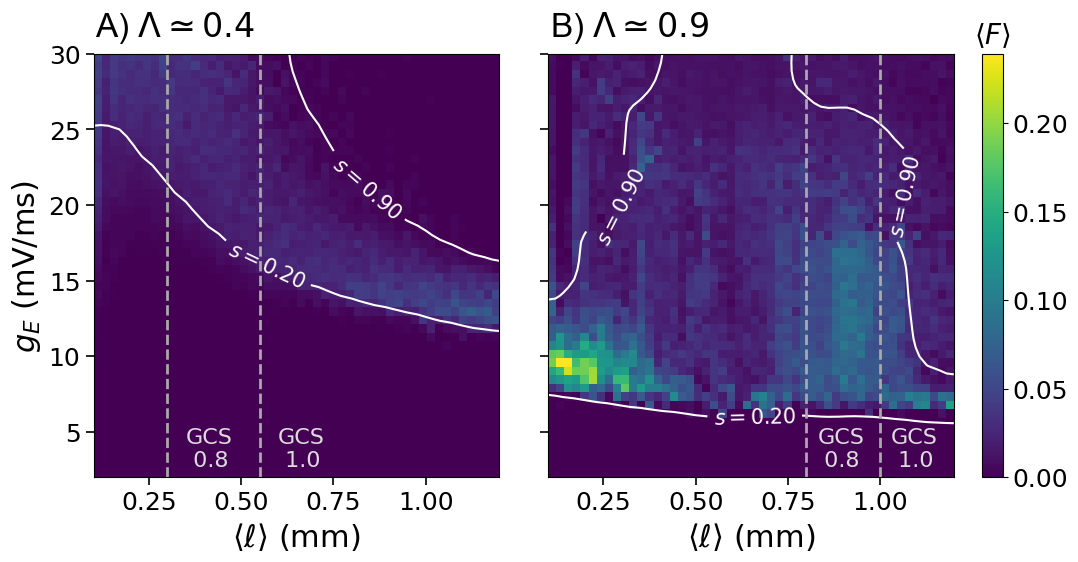

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from pathlib import Path
from matplotlib.pylab import seed
import numpy as np
import matplotlib.pyplot as plt
from pypalettes import load_cmap 
import importlib
import functions_create_networks as fcn
importlib.reload(fcn)
from numba import njit

# =========================
# OPCIONES
# =========================

# heatmap_value = "GC_fraction"        # "fano_factor" o "mean_peaks_height"
# heatmap_value = "mean_degree"        # "fano_factor" o "mean_peaks_height"
heatmap_value = "fano_factor"        # "fano_factor" o "mean_peaks_height"
# heatmap_value = "mean_peaks_height"  # "fano_factor" o "mean_peaks_height"
contour_value = "mean_peaks_height"  # "fano_factor" o "mean_peaks_height"

smooth_sigma = 2

# Si lo dejas en None, calcula niveles automáticamente
contour_levels = None
contour_levels = [0.2, 0.9]

labels = {
    "fano_factor": r"$F = \sigma^2/\mu$",
    "mean_peaks_height": r"$\langle GNA \rangle$"
}

# =========================
# CARGA DATOS
# =========================

mapdata_square120 = pd.read_csv("GNA_map_vsLength/2D_GNAmap_square_SW_rho71_s0.03_l1.00_mean.txt", sep="\t")
mapdata_square030 = pd.read_csv("GNA_map_vsLength/2D_GNAmap_square_SW_rho71_s0.70_l1.00_mean.txt", sep="\t")
# mapdata_square030 = pd.read_csv("GNA_map_vsLength/3D_GNAmap_cube_SW_rho1400_s0.03_sim0.txt", sep="\t")
# mapdata_square120 = pd.read_csv("GNA_map_vsLength/3D_GNAmap_cube_SW_rho1400_s0.45_sim0.txt", sep="\t")

def make_grid(df, value):
    pivot = df.pivot(
        index="MAX_EXC_WEIGHT",
        columns="axonal_length",
        values=value
    ).sort_index()

    x = pivot.columns.to_numpy(dtype=float)
    y = pivot.index.to_numpy(dtype=float)
    Z = pivot.to_numpy(dtype=float)

    return x, y, Z


# =========================
# MATRICES
# =========================

x_sq, y_sq, Z_sq_heat = make_grid(mapdata_square030, heatmap_value)
x_ci, y_ci, Z_ci_heat = make_grid(mapdata_square120, heatmap_value)

_, _, Z_sq_contour = make_grid(mapdata_square030, contour_value)
_, _, Z_ci_contour = make_grid(mapdata_square120, contour_value)

Z_sq_contour_smooth = gaussian_filter(Z_sq_contour, sigma=smooth_sigma)
Z_ci_contour_smooth = gaussian_filter(Z_ci_contour, sigma=smooth_sigma)

# Escala común del mapa de color
vmin = min(np.nanmin(Z_sq_heat), np.nanmin(Z_ci_heat))
vmax = max(np.nanmax(Z_sq_heat), np.nanmax(Z_ci_heat))

# Niveles automáticos para los contornos
if contour_levels is None:
    cmin = min(np.nanmin(Z_sq_contour_smooth), np.nanmin(Z_ci_contour_smooth))
    cmax = max(np.nanmax(Z_sq_contour_smooth), np.nanmax(Z_ci_contour_smooth))
    contour_levels = np.linspace(cmin, cmax, 6)[1:-1]


# =========================
# FIGURA
# =========================

fig, axs = plt.subplots(
    1, 2,
    figsize=(12, 5.5),
    sharex=True,
    sharey=True,
    gridspec_kw={"wspace": 0.12}
)

# Square
im0 = axs[0].imshow(
    Z_sq_heat,
    origin="lower",
    aspect="auto",
    extent=[x_sq.min(), x_sq.max(), y_sq.min(), y_sq.max()],
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    interpolation="nearest"
)

cs1 = axs[0].contour(
    x_sq,
    y_sq,
    Z_sq_contour_smooth,
    levels=contour_levels,
    colors="white",
    linewidths=1.5,
    linestyles="-"
)

# Circle
im1 = axs[1].imshow(
    Z_ci_heat,
    origin="lower",
    aspect="auto",
    extent=[x_ci.min(), x_ci.max(), y_ci.min(), y_ci.max()],
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    interpolation="nearest"
)

cs2 = axs[1].contour(
    x_ci,
    y_ci,
    Z_ci_contour_smooth,
    levels=contour_levels,
    colors="white",
    linewidths=1.5,
    linestyles="-"
)

axs[0].clabel(cs1, inline=True, fontsize=15, fmt=lambda x: fr"$s={x:.2f}$", inline_spacing=10)
axs[1].clabel(cs2, inline=True, fontsize=15, fmt=lambda x: fr"$s={x:.2f}$", inline_spacing=10)

# Títulos
axs[0].text(
    0.2, 1.02, "A) " + r"$\Lambda\simeq0.4$",
    transform=axs[0].transAxes,
    ha="center",
    va="bottom",
    fontsize=24,
    font="Arial",
    color = "black",
    bbox=dict(facecolor="white", alpha=0.0, edgecolor="none", pad=6)
)

axs[1].text(
    0.2, 1.02, "B) " + r"$\Lambda\simeq0.9$",
    transform=axs[1].transAxes,
    ha="center",
    va="bottom",
    fontsize=24,
    font="Arial",
    color = "black",
    bbox=dict(facecolor="white", alpha=0.0, edgecolor="none", pad=6)
)

# Ejes
for ax in axs:
    ax.set_xlabel(r"$\langle\ell\rangle$" + " (mm)", fontsize=22)
    ax.tick_params(axis="both", labelsize=18, length=6, width=1.2)

axs[0].set_ylabel(r"$g_E$" + " (mV/ms)", fontsize=22)

# Colorbar
cbar = fig.colorbar(
    im1,
    ax=axs,
    location="right",
    fraction=0.045,
    pad=0.03
)

ax.text(
    1.095,
    1.01,
    r"$\langle F \rangle$",
    transform=ax.transAxes,
    ha="center",
    va="bottom",
    fontsize=20,
    fontweight="bold",
    color="black",
    bbox=dict(
        facecolor="white",
        alpha=0.0,
        edgecolor="none",
        pad=6
    )
)
viridis = load_cmap("viridis")
axs[0].axvline(0.3, color='darkgray', linestyle="--", linewidth=2)
axs[0].axvline(0.55, color='darkgray', linestyle="--", linewidth=2)
axs[0].text(0.35, 2.7, f"GCS\n 0.8", fontsize=16, color='gainsboro')
axs[0].text(0.6, 2.7, f"GCS\n 1.0", fontsize=16, color='gainsboro')
axs[1].axvline(0.8, color='darkgray', linestyle="--", linewidth=2)
axs[1].axvline(1.0, color='darkgray', linestyle="--", linewidth=2)
axs[1].text(0.83, 2.7, f"GCS\n 0.8", fontsize=16, color='gainsboro')
axs[1].text(1.03, 2.7, f"GCS\n 1.0", fontsize=16, color='gainsboro')
# cbar.set_label(labels[heatmap_value], fontsize=22, labelpad=14)
# cbar.ax.set_title(labels[heatmap_value], fontsize=22, pad=14)
cbar.ax.tick_params(labelsize=18)
plt.savefig("2D_GNAmap_vs_Length.png", dpi=600, bbox_inches="tight", transparent=True)
plt.show()

# Gini color map (Fig.5)

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter


def plot_activity_panel(
    filename_left,
    filename_right,
    titles=("2D-Square", "3D-Cube"),
    heatmap_value="fano_factor",
    contour_value="mean_peaks_height",
    smooth_sigma=1.5,
    contour_levels=[0.2, 0.9],
    cmap="viridis",
    figsize=(12, 5.5)
):

    labels = {
        "fano_factor": r"$\langle F \rangle$",
        "mean_peaks_height": r"$\langle s \rangle$"
    }

    def make_grid(filename, value):
        df = pd.read_csv(filename, sep="\t")

        pivot = df.pivot(
            index="MAX_EXC_WEIGHT",
            columns="Gini",
            values=value
        ).sort_index()

        x = pivot.columns.to_numpy(dtype=float)
        y = pivot.index.to_numpy(dtype=float)
        Z = pivot.to_numpy(dtype=float)

        return x, y, Z

    # =========================
    # CARGA MATRICES
    # =========================

    x_left, y_left, Z_left_heat = make_grid(filename_left, heatmap_value)
    x_right, y_right, Z_right_heat = make_grid(filename_right, heatmap_value)

    _, _, Z_left_contour = make_grid(filename_left, contour_value)
    _, _, Z_right_contour = make_grid(filename_right, contour_value)

    Z_left_contour_smooth = gaussian_filter(Z_left_contour, sigma=smooth_sigma)
    Z_right_contour_smooth = gaussian_filter(Z_right_contour, sigma=smooth_sigma)

    # Escala común de color
    vmin = min(np.nanmin(Z_left_heat), np.nanmin(Z_right_heat))
    vmax = max(np.nanmax(Z_left_heat), np.nanmax(Z_right_heat))

    # Contornos automáticos
    # if contour_levels is None:
    #     cmin = min(
    #         np.nanmin(Z_left_contour_smooth),
    #         np.nanmin(Z_right_contour_smooth)
    #     )
    #     cmax = max(
    #         np.nanmax(Z_left_contour_smooth),
    #         np.nanmax(Z_right_contour_smooth)
    #     )
    #     contour_levels = np.linspace(cmin, cmax, 6)[1:-1]

    # =========================
    # FIGURA
    # =========================

    fig, axs = plt.subplots(
        1, 2,
        figsize=figsize,
        sharey=True,
        gridspec_kw={"wspace": 0.08}
    )

    data = [
        (axs[0], x_left, y_left, Z_left_heat, Z_left_contour_smooth, titles[0]),
        (axs[1], x_right, y_right, Z_right_heat, Z_right_contour_smooth, titles[1])
    ]

    for ax, x, y, Z_heat, Z_contour, title in data:

        im = ax.imshow(
            Z_heat,
            origin="lower",
            aspect="auto",
            extent=[
                x.min(),
                x.max(),
                y.min(),
                y.max()
            ],
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
            interpolation="nearest"
        )

        if contour_levels is not None:
            cs = ax.contour(
                x,
                y,
                Z_contour,
                levels=contour_levels,
                colors="white",
                linewidths=1.5,
                linestyles="-"
            )

            ax.clabel(
                cs,
                inline=True,
                fontsize=15,
                fmt="%.2f"
            )

        ax.text(
            0.13,
            1.01,
            title,
            transform=ax.transAxes,
            ha="center",
            va="bottom",
            fontsize=20,
            fontweight="bold",
            color="black",
            bbox=dict(
                facecolor="white",
                alpha=0.0,
                edgecolor="none",
                pad=6
            )
        )

        ax.set_xlabel(r"$\Lambda$", fontsize=22)

        ax.tick_params(
            axis="both",
            labelsize=16,
            length=6,
            width=1.2
        )

    axs[0].set_ylabel(r"$g_E$", fontsize=20)

    # Colorbar común
    cbar = fig.colorbar(
        im,
        ax=axs,
        location="right",
        fraction=0.045,
        pad=0.025
    )

    cbar.ax.set_title(
        labels[heatmap_value],
        fontsize=20,
        pad=14
    )

    cbar.ax.tick_params(labelsize=18)

    plt.savefig("fano_factor_panel_Gini.svg", dpi=300, bbox_inches="tight")
    plt.show()

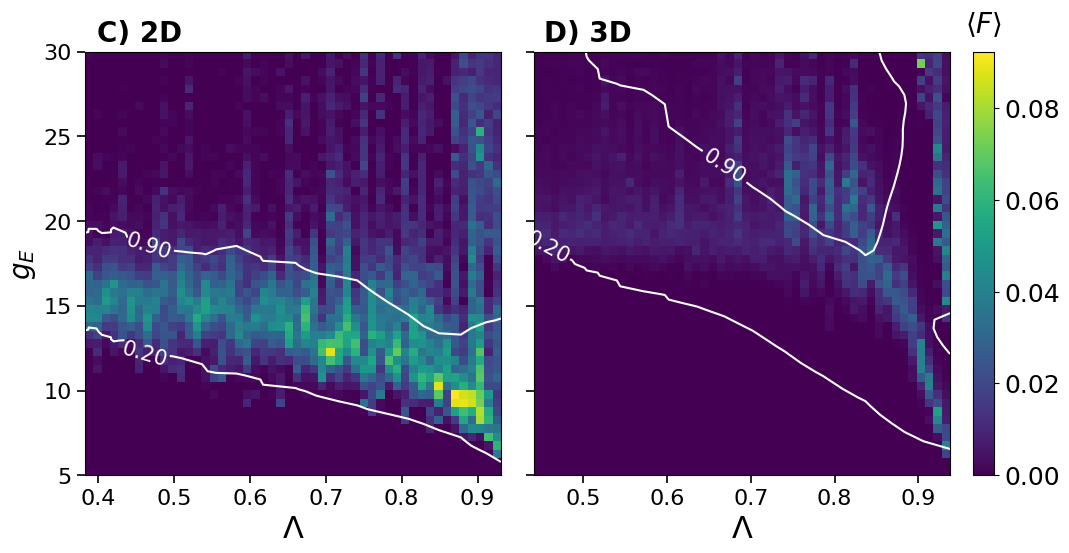

In [8]:
plot_activity_panel(
    filename_left="GNA_map_vsGini/GNAmap_square_SW_rho71_l1.00_mean.txt",
    filename_right="GNA_map_vsGini/3D_GNAmap_cube_SW_rho600_l1.00_mean.txt",
    titles=("C) 2D", "D) 3D"),
    heatmap_value="fano_factor",
    contour_value="mean_peaks_height",
    contour_levels=[0.2, 0.9]
)

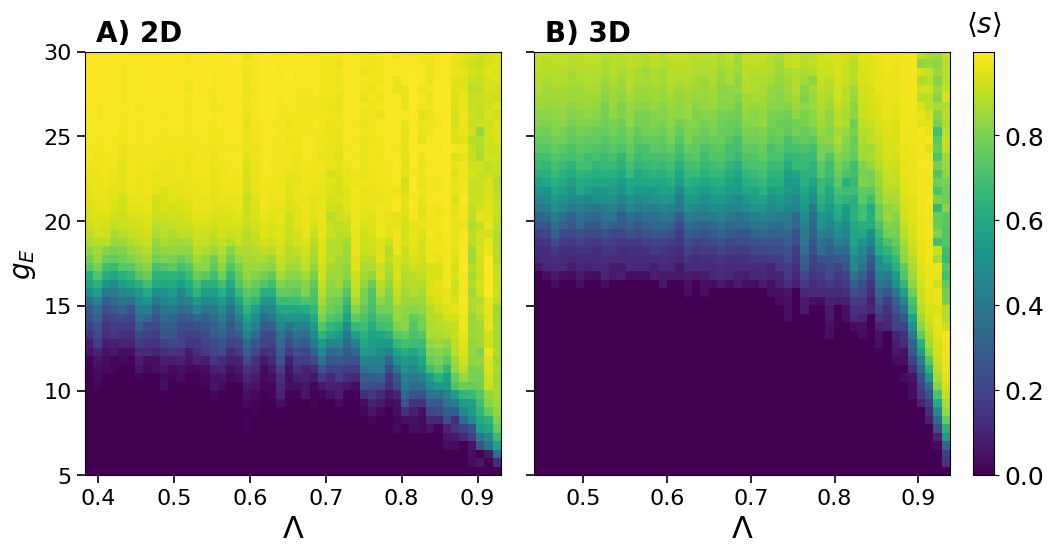

In [9]:
plot_activity_panel(
    filename_left="GNA_map_vsGini/GNAmap_square_SW_rho71_l1.00_mean.txt",
    filename_right="GNA_map_vsGini/3D_GNAmap_cube_SW_rho600_l1.00_mean.txt",
    titles=("A) 2D", "B) 3D"),
    heatmap_value="mean_peaks_height",
    contour_levels=None
)

# Functional analysis (Fig.6)

In [10]:
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import precision_recall_curve, average_precision_score
import numpy as np


def compute_roc(A, F):

    # -------------------------
    # Simetrizar estructura
    # -------------------------
    F = np.nan_to_num(F, nan=0.0)

    A = ((A + A.T) > 0).astype(int)

    # -------------------------
    # Score funcional
    # -------------------------

    F = np.abs(F)

    # -------------------------
    # Triángulo superior
    # -------------------------

    mask = np.triu(np.ones(A.shape, dtype=bool), k=1)

    y_true = A[mask]
    y_score = F[mask]

    # -------------------------
    # ROC
    # -------------------------

    fpr, tpr, thresholds = roc_curve(y_true, y_score)

    roc_auc = auc(fpr, tpr)

    return fpr, tpr, roc_auc, thresholds

def compute_precision_recall(A, F):

    F = np.nan_to_num(F, nan=0.0)
    A = ((A + A.T) > 0).astype(int)
    F = np.abs(F)

    mask = np.triu(np.ones(A.shape, dtype=bool), k=1)

    y_true = A[mask]
    y_score = F[mask]

    precision, recall, thresholds = precision_recall_curve(y_true, y_score)
    ap = average_precision_score(y_true, y_score)

    return precision, recall, ap, thresholds

def confusion_at_fpr(A, F, target_fpr=0.1):

    F = np.nan_to_num(F, nan=0.0)
    A = ((A + A.T) > 0).astype(int)
    F = np.abs(F)

    mask = np.triu(np.ones(A.shape, dtype=bool), k=1)

    y_true = A[mask]
    y_score = F[mask]

    fpr, tpr, thresholds = roc_curve(y_true, y_score)

    idx = np.argmin(np.abs(fpr - target_fpr))
    threshold = thresholds[idx]

    y_pred = (y_score >= threshold).astype(int)

    TP = np.sum((y_true == 1) & (y_pred == 1))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    FN = np.sum((y_true == 1) & (y_pred == 0))
    TN = np.sum((y_true == 0) & (y_pred == 0))

    return {
        "threshold": threshold,
        "fpr": FP / (FP + TN),
        "tpr": TP / (TP + FN),
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "TN": TN,
        "P": TP + FN,
        "N": FP + TN
    }

import matplotlib.pyplot as plt
import numpy as np

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

from mpl_toolkits.axes_grid1 import make_axes_locatable

from mpl_toolkits.axes_grid1 import make_axes_locatable

def plot_precision_recall(A, F, title="", savefig=False, dpi=600, filename="precision_recall.png"):

    precision, recall, ap, thresholds = compute_precision_recall(A, F)

    fig, ax = plt.subplots(figsize=(5, 4.5))

    ax.plot(recall, precision, lw=2.5)

    ax.set_xlabel("Recall / TPR", fontsize=18)
    ax.set_ylabel("Precision", fontsize=18)

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.05)

    ax.tick_params(axis="both", labelsize=16)

    ax.set_title(f"{title}\nAP = {ap:.3f}", fontsize=18, pad=12)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()

    if savefig:
        plt.savefig(filename, dpi=dpi, bbox_inches="tight")

    plt.show()

def plot_confusion_matrix_normalized(res, title="", savefig = False, dpi = 600, filename = "confusion_matrix.png"):

    # total = res["P"] + res["N"]

    # cm = np.array([
    #     [res["TP"] / total, res["FN"] / total],
    #     [res["FP"] / total, res["TN"] / total]
    # ])

    cm = np.array([
        [res["TP"] / res["P"], res["FN"] / res["P"]],
        [res["FP"] / res["N"], res["TN"] / res["N"]]
    ])

    labels = [["TPR", "FNR"],
              ["FPR", "TNR"]]

    fig, ax = plt.subplots(figsize=(5, 4.5))

    im = ax.imshow(cm, cmap="viridis", vmin=0, vmax=1, aspect="equal")

    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.08)
    cbar = plt.colorbar(im, cax=cax)
    cbar.set_label("Fraction", fontsize=20)
    cbar.ax.tick_params(labelsize=18)
    cbar.outline.set_edgecolor("#ccc")

    norm = mcolors.Normalize(vmin=0, vmax=1)
    cmap = plt.get_cmap("viridis")
    
    for i in range(2):
        for j in range(2):
            val = cm[i, j]
            r, g, b, _ = cmap(norm(val))
            luminance = 0.299 * r + 0.587 * g + 0.114 * b
            text_color = "white" if luminance < 0.5 else "#111"
            ax.text(
                j, i,
                f"{labels[i][j]}\n{100 * val:.1f}%",
                ha="center", va="center",
                fontsize=18,
                color=text_color,
                linespacing=1.6
            )
    

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["Positive", "Negative"], fontsize=18)
    ax.set_yticklabels(["Positive", "Negative"], fontsize=18, rotation=90, va="center")
    ax.tick_params(length=0)

    ax.set_xlabel("Predicted", fontsize=20, fontweight="medium", labelpad=8)
    ax.set_ylabel("Actual", fontsize=20, fontweight="medium", labelpad=8)

    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.set_title(title, fontsize=20, pad=14, fontweight="medium")

    plt.tight_layout()
    if savefig:
        plt.savefig(filename, dpi=dpi, bbox_inches='tight')
    plt.show()

In [11]:
import os

from pypalettes import load_cmap
def find_filename2D(parameters2D = None, sigma = 0.5, exc_weight = 8.5, sim_number = 0):

    if parameters2D is None:
        parameters2D = {
            "L": 3.0,
            "rho": 71,
            "soma_diameter": 0.015,
            "d_mean": 0.15,
            "d_sigma": 0.02,
            "l_mean": 1.00,
            "segment_length": 0.01,
            "sigma_axon_angle": 0.1,
            "agg": 1,
            "n_centers": 10,
            "base_sigma": 0.5,
            "BC_type": "SW",
            "geometry": "square"   # "square" or "circle"
    }

    parametersDynamics = {
        "max_exc_weight": 8.5,
        "max_inh_weight": 0.5,
        "noise_max": 3,
        "sim_time": 10000,
        "seed": 42
    }

    alpha = 0.2
    sim = sim_number

    calibration_filename = "data_for_figures/gini2D_n_grid13_calibration.txt"
    data = np.loadtxt(calibration_filename, skiprows=1)
    base_sigma_values = data[:,1]

    base_sigma_values = np.linspace(0.03, 0.7, 50)
    MAX_EXC_WEIGHT_values = np.linspace(5, 30.0, 50)


    base_sigma_target = sigma
    MAX_EXC_WEIGHT_target = exc_weight

    base_sigma = base_sigma_values[np.abs(base_sigma_values - base_sigma_target).argmin()]
    MAX_EXC_WEIGHT = MAX_EXC_WEIGHT_values[np.abs(MAX_EXC_WEIGHT_values - MAX_EXC_WEIGHT_target).argmin()]


    # ============================================================
    # FILENAMES
    # ============================================================


    filename_adj_2D = (
        f"2D_dynamics/networks_for_dynamics/"
        f"2D_adjacency_matrix_{parameters2D['geometry']}_{parameters2D['BC_type']}"
        f"_agg_nc{parameters2D['n_centers']}_s{base_sigma:.4f}"
        f"_L{parameters2D['L']:.1f}_rho{parameters2D['rho']:.0f}"
        f"_l{parameters2D['l_mean']:.2f}_d{parameters2D['d_mean']:.2f}"
        f"_a{alpha:.2f}_sim{sim}.txt"
    )

    filename_dyn_2D = (
        f"2D_dynamics/2D_dynamics_{parameters2D['geometry']}_{parameters2D['BC_type']}"
        f"_agg_nc{parameters2D['n_centers']}_s{base_sigma:.4f}"
        f"_L{parameters2D['L']:.1f}_rho{parameters2D['rho']:.0f}_l{parameters2D['l_mean']:.2f}_d{parameters2D['d_mean']:.2f}"
        f"_a{alpha:.2f}_exc{MAX_EXC_WEIGHT:.3f}_sim{sim}.txt"
    )

    print(f"Buscando archivos:\n{filename_adj_2D}\n{filename_dyn_2D}")

    if not os.path.exists(filename_adj_2D):
        print(f"Archivo no encontrado: {filename_adj_2D}")
    if not os.path.exists(filename_dyn_2D):
        print(f"Archivo no encontrado: {filename_dyn_2D}")
        
    return filename_adj_2D, filename_dyn_2D


def find_filename3D(parameters3D = None, sigma = 0.04, exc_weight = 8.5, sim_number = 0):

    if parameters3D is None:
        parameters3D = {
            "L": 3.0, # Length of the square domain (mm) or diameter of the circular domain (mm)
            "height": 1.0, # Height of the cylinder domain (mm), only used if geometry is "cylinder"
            "rho": 600, # Neuron density (neurons/mm^2)
            "soma_diameter": 0.015, # Diameter of the soma (mm)
            "d_mean": 0.15, # Dendritic tree diameter (mm) Gaussian distribution
            "d_sigma": 0.02, # Standard deviation of the dendritic tree diameter (mm)
            "l_mean": 1.00, # Mean axon length (mm) Rayleigh distribution
            "segment_length": 0.01, # Segment length for axon growth (mm)
            "sigma_pol": 0.1, # Standard deviation of the axon angle (radians)
            "sigma_azi": 0.1, # Standard deviation of the azimuthal angle (radians)
            "agg": 1, # Control parameter for the aggregation of neurons
            "n_centers": 80, # Number of centers for the aggregation of neurons
            "base_sigma": 0.04, # Base standard deviation for aggregation centers (mm)
            "BC_type": "SW",  # Boundary conditions type (PBC: Periodic Boundary Conditions, SW: Sticky Walls)
            "geometry": "cube", # Geometry of the domain (cube or sphere)
            "seed": 0,
    }

    parametersDynamics = {
        "max_exc_weight": 8.5,
        "max_inh_weight": 0.5,
        "noise_max": 3,
        "sim_time": 10000,
        "seed": 42
    }

    alpha = 0.2
    sim = sim_number

    calibration_filename = "data_for_figures/gini3D_n_grid13_calibration.txt"
    data = np.loadtxt(calibration_filename, skiprows=1)
    base_sigma_values = data[:,1]

    base_sigma_values = np.linspace(0.03, 0.7, 50)
    MAX_EXC_WEIGHT_values = np.linspace(5, 30.0, 50)


    base_sigma_target = sigma
    MAX_EXC_WEIGHT_target = exc_weight

    base_sigma = base_sigma_values[np.abs(base_sigma_values - base_sigma_target).argmin()]
    MAX_EXC_WEIGHT = MAX_EXC_WEIGHT_values[np.abs(MAX_EXC_WEIGHT_values - MAX_EXC_WEIGHT_target).argmin()]

    sunset2 = load_cmap("Sunset2", cmap_type="continuous")

    # ============================================================
    # FILENAMES
    # ============================================================

    filename_adj_3D = (
        f"3D_dynamics/networks_for_dynamics/"
        f"3D_adjacency_matrix_{parameters3D['geometry']}_{parameters3D['BC_type']}"
        f"_agg_nc{parameters3D['n_centers']}_s{base_sigma:.4f}"
        f"_L{parameters3D['L']:.1f}_h{parameters3D['height']:.2f}_rho{parameters3D['rho']:.0f}"
        f"_l{parameters3D['l_mean']:.2f}_d{parameters3D['d_mean']:.2f}"
        f"_a{alpha:.2f}_sim{sim}.txt"
    )

    filename_dyn_3D = (
        f"3D_dynamics/3D_dynamics_{parameters3D['geometry']}_{parameters3D['BC_type']}"
        f"_agg_nc{parameters3D['n_centers']}_s{base_sigma:.4f}"
        f"_L{parameters3D['L']:.1f}_h{parameters3D['height']:.2f}_rho{parameters3D['rho']:.0f}"
        f"_l{parameters3D['l_mean']:.2f}_d{parameters3D['d_mean']:.2f}"
        f"_a{alpha:.2f}_exc{MAX_EXC_WEIGHT:.3f}_sim{sim}.txt"
    )

    print(f"Buscando archivos:\n{filename_adj_3D}\n{filename_dyn_3D}")
    if not os.path.exists(filename_adj_3D):
        print(f"Archivo no encontrado: {filename_adj_3D}")
    if not os.path.exists(filename_dyn_3D):
        print(f"Archivo no encontrado: {filename_dyn_3D}")
    return filename_adj_3D, filename_dyn_3D

## Modularity $Q$ and Clustering $C$ color map

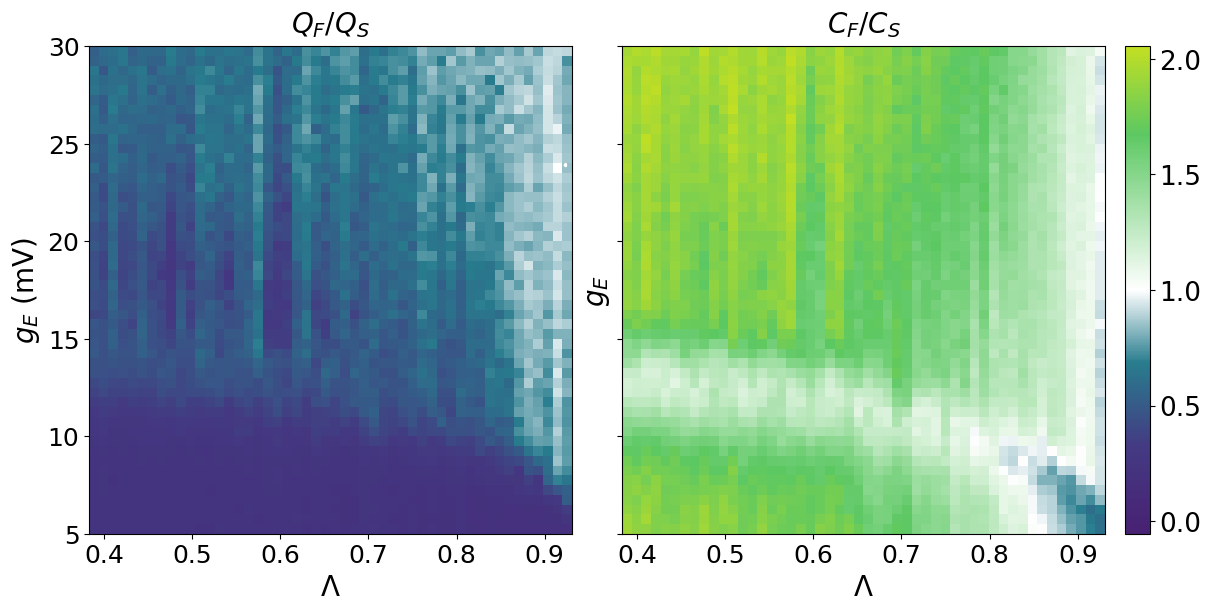

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import LinearSegmentedColormap

viridis = load_cmap("viridis", cmap_type="continuous")

viridis_div = LinearSegmentedColormap.from_list(
    "viridis_div",
    [
        (0.00, viridis(0.0)),   # morado oscuro
        (0.18, viridis(0.1)),   # azul-morado
        (0.35, viridis(0.4)),   # azul/verde oscuro
        (0.50, "white"),        # igualdad = 1
        # (0.65, viridis(0.60)),   # verde
        (0.82, viridis(0.8)),   # verde-amarillo
        (1.00, viridis(1.00)),   # amarillo
    ],
    N=256
)

# ==========================================================
# Archivos
# ==========================================================
map_modularity = "data_for_figures/modularity_map_2D_average.txt"
map_clustering = "data_for_figures/clustering_map_2D_average.txt"

# ==========================================================
# Función para cargar el mapa
# ==========================================================
def load_map(filename, value_column):
    df = pd.read_csv(filename, sep=r"\s+")

    pivot = (
        df.pivot_table(
            index="exc_weight",
            columns="gini",
            values=value_column,
            aggfunc="mean"
        )
        .sort_index()
        .sort_index(axis=1)
    )

    x = pivot.columns.to_numpy(dtype=float)
    y = pivot.index.to_numpy(dtype=float)
    Z = pivot.to_numpy(dtype=float)

    # Suavizado ligero
    Z = gaussian_filter(Z, sigma=0.01)

    return x, y, Z

# ==========================================================
# Cargar datos
# ==========================================================
xM, yM, ZM = load_map(map_modularity, "modF/modA")
xC, yC, ZC = load_map(map_clustering, "clusF/clusA")

# ==========================================================
# Escala divergente centrada en 1
# ==========================================================
delta = max(
    1 - np.nanmin(ZM),
    np.nanmax(ZM) - 1,
    1 - np.nanmin(ZC),
    np.nanmax(ZC) - 1,
)

norm = TwoSlopeNorm(
    vmin=1 - delta,
    vcenter=1.0,
    vmax=1 + delta
)

# ==========================================================
# Figura
# ==========================================================
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 6),
    constrained_layout=True, 
    sharey=True
)

# ==========================================================
# Modularity
# ==========================================================

cmap = viridis_div
im1 = axes[0].imshow(
    ZM,
    origin="lower",
    aspect="auto",
    extent=[xM.min(), xM.max(), yM.min(), yM.max()],
    cmap=cmap,
    norm=norm
)

axes[0].set_xlabel(r"$\Lambda$", fontsize=20)
axes[0].set_ylabel(r"$g_E$" + " (mV)", fontsize=20)
axes[0].tick_params(labelsize=18)
axes[0].set_title(r"$Q_F/Q_S$", fontsize=20, pad = 10)

# Contorno donde ambas modularidades son iguales
XM, YM = np.meshgrid(xM, yM)
axes[0].contour(
    XM,
    YM,
    ZM,
    levels=[1],
    colors="white",
    linewidths=2
)


# ==========================================================
# Clustering
# ==========================================================
im2 = axes[1].imshow(
    ZC,
    origin="lower",
    aspect="auto",
    extent=[xC.min(), xC.max(), yC.min(), yC.max()],
    cmap=cmap,
    norm=norm
)

axes[1].set_xlabel(r"$\Lambda$", fontsize=20)
axes[1].set_ylabel(r"$g_E$", fontsize=20)
axes[1].tick_params(labelsize=18)
axes[1].set_title(r"$C_F/C_S$", fontsize=20, pad = 10)
# Contorno donde ambos clustering son iguales
XC, YC = np.meshgrid(xC, yC)
# axes[1].contour(
#     XC,
#     YC,
#     ZC,
#     levels=[1],
#     colors="white",
#     linewidths=2
# )

# cbar2 = fig.colorbar(im2, ax=axes[1], pad=0.02)
# cbar2.set_label(r"$C_F/C_S$", fontsize=28)
# cbar2.ax.tick_params(labelsize=24)
cbar = fig.colorbar(
    im2,
    ax=axes,
    pad=0.02,
    fraction=0.04
)

# cbar.set_label(
#     r"$Q_F/Q_S$   or   $C_F/C_S$",
#     fontsize=28
# )

cbar_ticks = [0, 0.5, 1, 1.5, 2]
cbar.set_ticks(cbar_ticks)
cbar.ax.tick_params(labelsize=19)
# ==========================================================
# Guardar
# ==========================================================
plt.savefig(
    "modularity_clustering_panel.png",
    dpi=600,
    bbox_inches="tight",
    transparent=True
)

plt.show()

## ROC curve 

In [13]:

# -----------------------------
# Parámetros
# -----------------------------

import importlib
import functions_create_networks as fcn
importlib.reload(fcn)

sigma_2D_1 = 0.7
exc_weight_2D_1 = 16

sigma_2D_2 = 0.03
exc_weight_2D_2 = 10

sigma_3D_1 = 0.7
exc_weight_3D_1 = 23

sigma_3D_2 = 0.03
exc_weight_3D_2 = 10

SIM_TIME = 10000

# sigma_2D_1 = 0.7
# exc_weight_2D_1 = 15

# sigma_2D_2 = 0.03
# exc_weight_2D_2 = 10

# sigma_3D_1 = 0.7
# exc_weight_3D_1 = 23

# sigma_3D_2 = 0.03
# exc_weight_3D_2 = 10
# -----------------------------
# Ficheros
# -----------------------------

filename_adj_2D_1, filename_dyn_2D_1 = find_filename2D(
    sigma=sigma_2D_1,
    exc_weight=exc_weight_2D_1
)

filename_adj_2D_2, filename_dyn_2D_2 = find_filename2D(
    sigma=sigma_2D_2,
    exc_weight=exc_weight_2D_2
)

filename_adj_3D_1, filename_dyn_3D_1 = find_filename3D(
    sigma=sigma_3D_1,
    exc_weight=exc_weight_3D_1
)

filename_adj_3D_2, filename_dyn_3D_2 = find_filename3D(
    sigma=sigma_3D_2,
    exc_weight=exc_weight_3D_2
)


# -----------------------------
# Cargar matrices estructurales
# -----------------------------

A_2D_1 = fcn.load_A(filename_adj_2D_1)
A_2D_2 = fcn.load_A(filename_adj_2D_2)
A_3D_1 = fcn.load_A(filename_adj_3D_1)
A_3D_2 = fcn.load_A(filename_adj_3D_2)

A_2D_1_CG = fcn.get_GC(A_2D_1)
A_2D_2_CG = fcn.get_GC(A_2D_2)
A_3D_1_CG = fcn.get_GC(A_3D_1)
A_3D_2_CG = fcn.get_GC(A_3D_2)


# -----------------------------
# Construir matrices funcionales
# -----------------------------

F_2D_1 = fcn.build_F_matrix(
    filename_dyn_2D_1,
    SIM_TIME=SIM_TIME,
    N=A_2D_1_CG.shape[0]
)[0]

F_2D_2 = fcn.build_F_matrix(
    filename_dyn_2D_2,
    SIM_TIME=SIM_TIME,
    N=A_2D_2_CG.shape[0]
)[0]

F_3D_1 = fcn.build_F_matrix(
    filename_dyn_3D_1,
    SIM_TIME=SIM_TIME,
    N=A_3D_1_CG.shape[0]
)[0]

F_3D_2 = fcn.build_F_matrix(
    filename_dyn_3D_2,
    SIM_TIME=SIM_TIME,
    N=A_3D_2_CG.shape[0]
)[0]


# -----------------------------
# Comprobar tamaños
# -----------------------------

print("2D 1:", A_2D_1_CG.shape, F_2D_1.shape)
print("2D 2:", A_2D_2_CG.shape, F_2D_2.shape)
print("3D 1:", A_3D_1_CG.shape, F_3D_1.shape)
print("3D 2:", A_3D_2_CG.shape, F_3D_2.shape)


# -----------------------------
# ROC
# -----------------------------

fpr_2D_1, tpr_2D_1, roc_auc_2D_1, thresholds_2D_1 = compute_roc(
    A_2D_1_CG,
    F_2D_1
)

fpr_2D_2, tpr_2D_2, roc_auc_2D_2, thresholds_2D_2 = compute_roc(
    A_2D_2_CG,
    F_2D_2
)

fpr_3D_1, tpr_3D_1, roc_auc_3D_1, thresholds_3D_1 = compute_roc(
    A_3D_1_CG,
    F_3D_1
)

fpr_3D_2, tpr_3D_2, roc_auc_3D_2, thresholds_3D_2 = compute_roc(
    A_3D_2_CG,
    F_3D_2
)

precision_2D_1, recall_2D_1, ap_2D_1, thresholds_pr_2D_1 = compute_precision_recall(
    A_2D_1_CG,
    F_2D_1
)
precision_2D_2, recall_2D_2, ap_2D_2, thresholds_pr_2D_2 = compute_precision_recall(
    A_2D_2_CG,
    F_2D_2
)
precision_3D_1, recall_3D_1, ap_3D_1, thresholds_pr_3D_1 = compute_precision_recall(
    A_3D_1_CG,
    F_3D_1
)
precision_3D_2, recall_3D_2, ap_3D_2, thresholds_pr_3D_2 = compute_precision_recall(
    A_3D_2_CG,
    F_3D_2
)

# -----------------------------
# Confusion matrices a FPR = 0.1
# -----------------------------

res_2D_1 = confusion_at_fpr(A_2D_1_CG, F_2D_1, target_fpr=0.1)
res_2D_2 = confusion_at_fpr(A_2D_2_CG, F_2D_2, target_fpr=0.1)
res_3D_1 = confusion_at_fpr(A_3D_1_CG, F_3D_1, target_fpr=0.1)
res_3D_2 = confusion_at_fpr(A_3D_2_CG, F_3D_2, target_fpr=0.1)

Buscando archivos:
2D_dynamics/networks_for_dynamics/2D_adjacency_matrix_square_SW_agg_nc10_s0.7000_L3.0_rho71_l1.00_d0.15_a0.20_sim0.txt
2D_dynamics/2D_dynamics_square_SW_agg_nc10_s0.7000_L3.0_rho71_l1.00_d0.15_a0.20_exc16.224_sim0.txt
Buscando archivos:
2D_dynamics/networks_for_dynamics/2D_adjacency_matrix_square_SW_agg_nc10_s0.0300_L3.0_rho71_l1.00_d0.15_a0.20_sim0.txt
2D_dynamics/2D_dynamics_square_SW_agg_nc10_s0.0300_L3.0_rho71_l1.00_d0.15_a0.20_exc10.102_sim0.txt
Buscando archivos:
3D_dynamics/networks_for_dynamics/3D_adjacency_matrix_cube_SW_agg_nc80_s0.7000_L3.0_h1.00_rho600_l1.00_d0.15_a0.20_sim0.txt
3D_dynamics/3D_dynamics_cube_SW_agg_nc80_s0.7000_L3.0_h1.00_rho600_l1.00_d0.15_a0.20_exc22.857_sim0.txt
Buscando archivos:
3D_dynamics/networks_for_dynamics/3D_adjacency_matrix_cube_SW_agg_nc80_s0.0300_L3.0_h1.00_rho600_l1.00_d0.15_a0.20_sim0.txt
3D_dynamics/3D_dynamics_cube_SW_agg_nc80_s0.0300_L3.0_h1.00_rho600_l1.00_d0.15_a0.20_exc10.102_sim0.txt


c:\Users\Usuario\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\lib\_function_base_impl.py:3063: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\Usuario\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\lib\_function_base_impl.py:3064: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
c:\Users\Usuario\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\lib\_function_base_impl.py:3063: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\Usuario\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\lib\_function_base_impl.py:3064: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
c:\Users\Usuario\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\lib\_function_base_impl.py:3063: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\Usuario\AppData\Local\Programs\Python\Python31

2D 1: (629, 629) (629, 629)
2D 2: (638, 638) (638, 638)
3D 1: (4979, 4979) (4979, 4979)
3D 2: (5395, 5395) (5395, 5395)


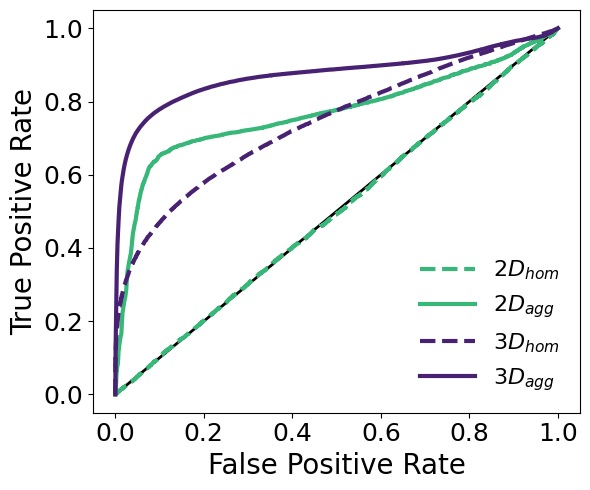

(array([-0.2,  0. ,  0.2,  0.4,  0.6,  0.8,  1. ,  1.2]),
 [Text(0, -0.2, '−0.2'),
  Text(0, 0.0, '0.0'),
  Text(0, 0.2, '0.2'),
  Text(0, 0.4000000000000001, '0.4'),
  Text(0, 0.6000000000000001, '0.6'),
  Text(0, 0.8, '0.8'),
  Text(0, 1.0000000000000002, '1.0'),
  Text(0, 1.2000000000000002, '1.2')])

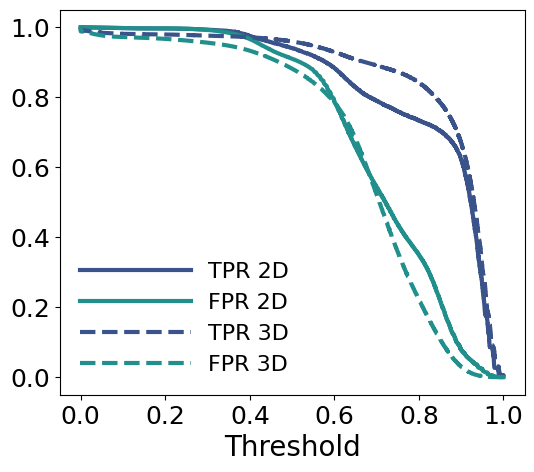

In [14]:
from pypalettes import load_cmap
import matplotlib.pyplot as plt
viridis = load_cmap("viridis", cmap_type="continuous")

plt.figure(figsize=(6, 5))
plt.plot([0, 1], [0, 1], '-', color='black', lw=2)
plt.plot(fpr_2D_1, tpr_2D_1, label=r"$2D_{hom}$", color = viridis(0.7), lw = 3, ls ="--")
plt.plot(fpr_2D_2, tpr_2D_2, label=r"$2D_{agg}$", color = viridis(0.7), lw = 3, ls ="-")
plt.plot(fpr_3D_1, tpr_3D_1, label=r"$3D_{hom}$", color = viridis(0.0), lw = 3, ls ="--")
plt.plot(fpr_3D_2, tpr_3D_2, label=r"$3D_{agg}$", color = viridis(0.0), lw = 3, ls ="-")
plt.legend(loc='lower right', fontsize = 16, frameon = False, handlelength=2.5)
plt.xlabel('False Positive Rate', fontsize = 20)
plt.ylabel('True Positive Rate', fontsize = 20)
plt.xticks(fontsize = 18)
plt.yticks(fontsize = 18)
plt.tight_layout()
plt.savefig("roc_curves.png", dpi =600, bbox_inches='tight', transparent=True)
plt.show()


plt.figure(figsize=(6, 5))
plt.plot(thresholds_2D_2, tpr_2D_2, color = viridis(0.2), lw = 3, label = "TPR 2D")
plt.plot(thresholds_2D_2, fpr_2D_2, color = viridis(0.5), lw = 3, label = "FPR 2D")
plt.plot(thresholds_3D_2, tpr_3D_2, color = viridis(0.2), lw = 3, ls = "--", label = "TPR 3D")
plt.plot(thresholds_3D_2, fpr_3D_2, color = viridis(0.5), lw = 3, ls = "--", label = "FPR 3D")
# plt.ylabel('False Positive Rate', fontsize = 20)
plt.xlabel('Threshold', fontsize = 20)
plt.legend(loc='best', fontsize = 16, frameon = False, handlelength=5)
plt.xticks(fontsize = 18)
plt.yticks(fontsize = 18)
# Sacar estas curvas para los axones rectos, mirar el clustering y la global effficiency. Mirar la modularidad y clustering de la estructural y funcional. Para apoyar el resultado de los mapas. Mapa Q_funcional/ Q_estrcutural. Mapa Clustering_funcioanl/Clustering_estructural

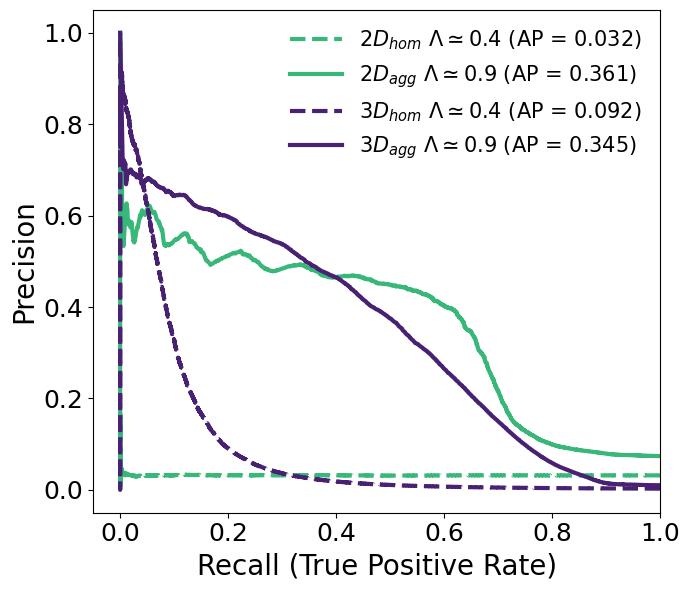

In [15]:

plt.figure(figsize=(7, 6))

plt.plot(
    recall_2D_1, precision_2D_1,
    label=rf"$2D_{{hom}}\ \Lambda\simeq0.4$ (AP = {ap_2D_1:.3f})",
    color=viridis(0.7),
    lw=3,
    ls="--"
)

plt.plot(
    recall_2D_2, precision_2D_2,
    label=rf"$2D_{{agg}}\ \Lambda\simeq0.9$ (AP = {ap_2D_2:.3f})",
    color=viridis(0.7),
    lw=3,
    ls="-"
)

plt.plot(
    recall_3D_1, precision_3D_1,
    label=rf"$3D_{{hom}}\ \Lambda\simeq0.4$ (AP = {ap_3D_1:.3f})",
    color=viridis(0.0),
    lw=3,
    ls="--"
)

plt.plot(
    recall_3D_2, precision_3D_2,
    label=rf"$3D_{{agg}}\ \Lambda\simeq0.9$ (AP = {ap_3D_2:.3f})",
    color=viridis(0.0),
    lw=3,
    ls="-"
)

plt.legend(
    loc="upper right",
    fontsize=15,
    frameon=False,
    handlelength=2.5
)

plt.xlabel("Recall (True Positive Rate)", fontsize=20)
plt.ylabel("Precision", fontsize=20)

plt.xlim(-0.05, 1)
plt.ylim(-0.05, 1.05)

plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

plt.tight_layout()

plt.savefig(
    "precision_recall_curves.png",
    dpi=600,
    bbox_inches="tight", 
    transparent=True
)

plt.show()

## TPR at FPR 0.1 

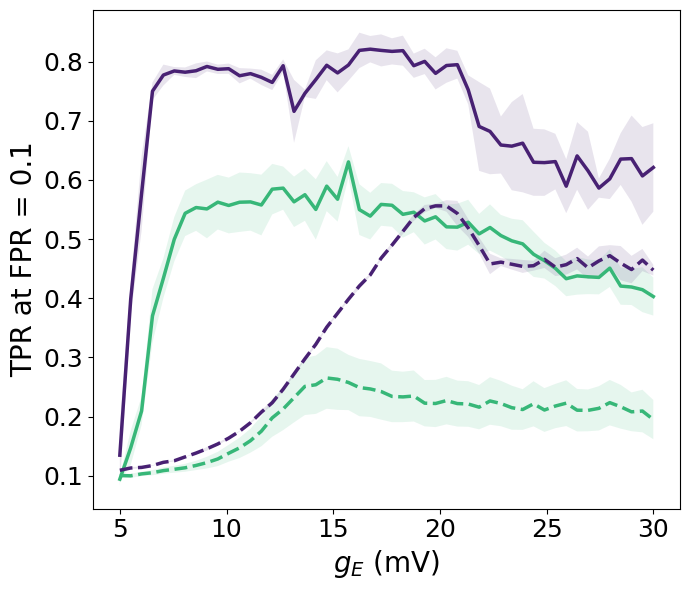

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pypalettes import load_cmap
output_filename2D = "data_for_figures/2D_roc_tpr_at_fpr0.1_curves_average2.txt"
output_filename3D = "data_for_figures/3D_roc_tpr_at_fpr0.1_curves_average_FINAL.txt"

df2D = pd.read_csv(output_filename2D, sep="\t")
df3D = pd.read_csv(output_filename3D, sep="\t")

viridis = load_cmap("viridis", cmap_type="continuous")

color2D = viridis(0.7)
color3D = viridis(0.0)

# Ajusta estos valores si en tus ficheros usas otros sigmas
sigma_random = 0.03
sigma_agg = 0.7

def get_style_label(base_sigma, dim):
    if np.isclose(base_sigma, sigma_random):
        linestyle = "-"
        label = rf"${dim}D_{{agg}}\ \Lambda\simeq0.9$"
    elif np.isclose(base_sigma, sigma_agg):
        linestyle = "--"
        label = rf"${dim}D_{{hom}}\ \Lambda\simeq0.3$"
    else:
        linestyle = "-"
        label = rf"${dim}D,\ \sigma={base_sigma:.3f}$"

    return linestyle, label


plt.figure(figsize=(7, 6))

# =========================
# 2D
# =========================

for base_sigma, group in df2D.groupby("base_sigma"):

    group = group.sort_values("MAX_EXC_WEIGHT")

    x = group["MAX_EXC_WEIGHT"].to_numpy()
    y = group["tpr_at_fpr0.1_mean"].to_numpy()
    yerr = group["tpr_at_fpr0.1_std"].to_numpy() / np.sqrt(10)

    linestyle, label = get_style_label(base_sigma, dim=2)

    plt.plot(
        x, y,
        lw=2.5,
        ls=linestyle,
        color=color2D,
        label=label
    )

    plt.fill_between(
        x,
        y - yerr,
        y + yerr,
        alpha=0.12,
        color=color2D,
        edgecolor="none"
    )


# =========================
# 3D
# =========================

for base_sigma, group in df3D.groupby("base_sigma"):

    group = group.sort_values("MAX_EXC_WEIGHT")

    x = group["MAX_EXC_WEIGHT"].to_numpy()
    y = group["tpr_at_fpr0.1_mean"].to_numpy()
    yerr = group["tpr_at_fpr0.1_std"].to_numpy() / np.sqrt(2)

    linestyle, label = get_style_label(base_sigma, dim=3)

    plt.plot(
        x, y,
        lw=2.5,
        ls=linestyle,
        color=color3D,
        label=label
    )

    plt.fill_between(
        x,
        y - yerr,
        y + yerr,
        alpha=0.12,
        color=color3D,
        edgecolor="none"
    )


plt.xlabel(r"$g_E$" + " (mV)", fontsize=20)
plt.ylabel(r"TPR at FPR = 0.1", fontsize=20)

plt.xticks([5, 10, 15, 20, 25, 30], fontsize=18)
plt.yticks(fontsize=18)

# plt.legend(
#     fontsize=14,
#     frameon=False,
#     handlelength=2.0
# )

plt.tight_layout()
plt.savefig(
    "roc_tpr_at_fpr0.1_curves_average.png",
    dpi=600,
    bbox_inches="tight", 
    transparent=True
)

plt.show()

